# Clasificación de gatos y perros mediante fine tuning de redes convolucionales preentrenadas

### Juan Sebastian Garcia Perez - Sebastian Hernandez Diaz

Problema: dada la fotografía de una mascota, determinar automáticamente si es un gato o un perro. Aprendizaje supervisado de clasificación binaria de imágenes.

Dominio: Visión artificial, clasificación de imágenes de animales domésticos.

Utilidad: Automatizar el etiquetado de fotos de mascotas. Puede servir por ejemplo en sistemas de archivos locales o en la nube, para que al buscar "perro" o "gato" salgan las fotos que tenemos guardadas de cada animal (por ejemplo en la galería del celular o en servicios cloud que no tengan esta funcionalidad).

Base de datos: Cats vs Dogs: 23262 fotos a color y 1 variable de salida categórica binaria. BD publicada en https://www.tensorflow.org/datasets/catalog/cats_vs_dogs.

Modelos entrenados: VGG16 y ResNet50 preentrenadas con ImageNet, ajustadas con fine tuning y búsqueda en malla de hiperparámetros.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds

from sklearn.model_selection import ParameterGrid
from sklearn.metrics import classification_report, confusion_matrix

%matplotlib inline

RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

print("TensorFlow:", tf.__version__)
print("GPU disponible:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow: 2.19.0
GPU disponible: True


# 2. Descripción de la BD

| Característica | Valor |
|---|---|
| Imágenes | 23262 fotos JPEG a color |
| Variable de entrada | image: matriz de píxeles de alto x ancho x 3 canales (RGB), enteros de 0 a 255 |
| Variable de salida | label (binaria) (cat / dog) |
| Tamaño de las imágenes | Variable entre 4 y 500 píxeles de ancho y largo (mediana 467 x 375) |
| Imágenes dañadas | 1738 de las 25000 originales, ya eliminadas por TensorFlow Datasets |
| Reparto de clases | 11658 gatos (50.1%), 11604 perros (49.9%) |
| Particiones de origen | Solo trae train, la separación en entrenamiento, validación y prueba la hacemos nosotros |

Variable de salida (label):

| Aspecto | label |
|---|---|
| Qué es | La especie del animal de la foto |
| Tipo | Categórica nominal (sin orden) y binaria |
| Valores | cat (11658 imágenes, 50.1 %) dog (11604 imágenes, 49.9 %) |
| Codificación | cat -> 0, dog -> 1 (ya viene codificada) |


# 3. Carga de los datos

La BD se descarga directamente desde TensorFlow Datasets. Como solo trae la partición train, la dividimos en 70 % para entrenamiento, 15 % para validación (elegir hiperparámetros y modelo) y 15 % para prueba (evaluación final).

In [2]:
(ds_train, ds_val, ds_test), info = tfds.load(
    "cats_vs_dogs",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True, with_info=True)

CLASES = ["gato", "perro"]

print("etiquetas originales:", info.features["label"].names)
print("imagenes totales:", info.splits["train"].num_examples)
print("entrenamiento:", len(ds_train), ", validacion:", len(ds_val), ", prueba:", len(ds_test))

etiquetas originales: ['cat', 'dog']
imagenes totales: 23262
entrenamiento: 16283 , validacion: 3490 , prueba: 3489


# 4. Análisis exploratorio de datos (EDA)

## 4.1 Estructura de una imagen

FeaturesDict({
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'image/filename': Text(shape=(), dtype=string),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
})

forma (alto, ancho, canales): (262, 350, 3) , tipo: uint8
valor minimo: 0 , valor maximo: 255
etiqueta: 1 -> perro


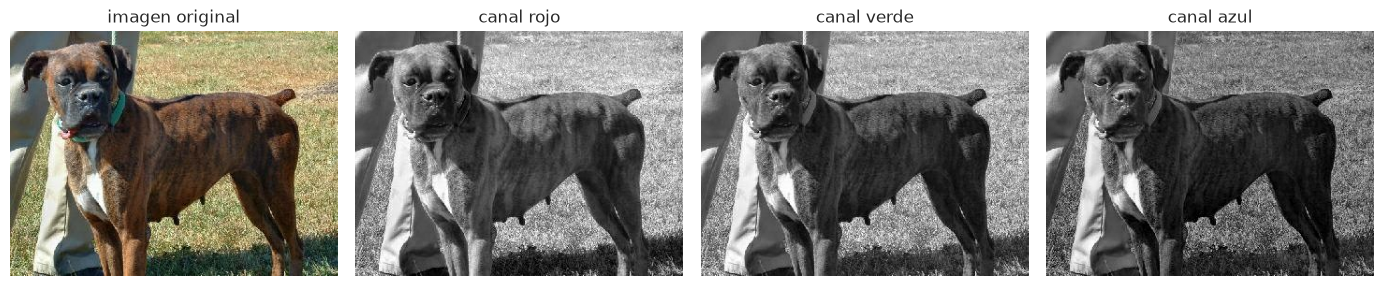

In [3]:
print(info.features)

imagen, etiqueta = next(iter(tfds.as_numpy(ds_train.take(1))))

print()
print("forma (alto, ancho, canales):", imagen.shape, ", tipo:", imagen.dtype)
print("valor minimo:", imagen.min(), ", valor maximo:", imagen.max())
print("etiqueta:", etiqueta, "->", CLASES[etiqueta])

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(imagen)
axes[0].set_title("imagen original")
for i, canal in enumerate(["rojo", "verde", "azul"]):
    axes[i + 1].imshow(imagen[:, :, i], cmap="gray")
    axes[i + 1].set_title("canal " + canal)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Cada imagen es una matriz de NumPy de tres dimensiones (alto, ancho y 3 canales de color) con enteros de 0 a 255. En la descripción el alto y el ancho aparecen como None porque cambian de una foto a otra. Los tres canales se parecen mucho entre sí, lo que indica que la información útil está en las formas y texturas más que en el color.

## 4.2 Imágenes de cada clase

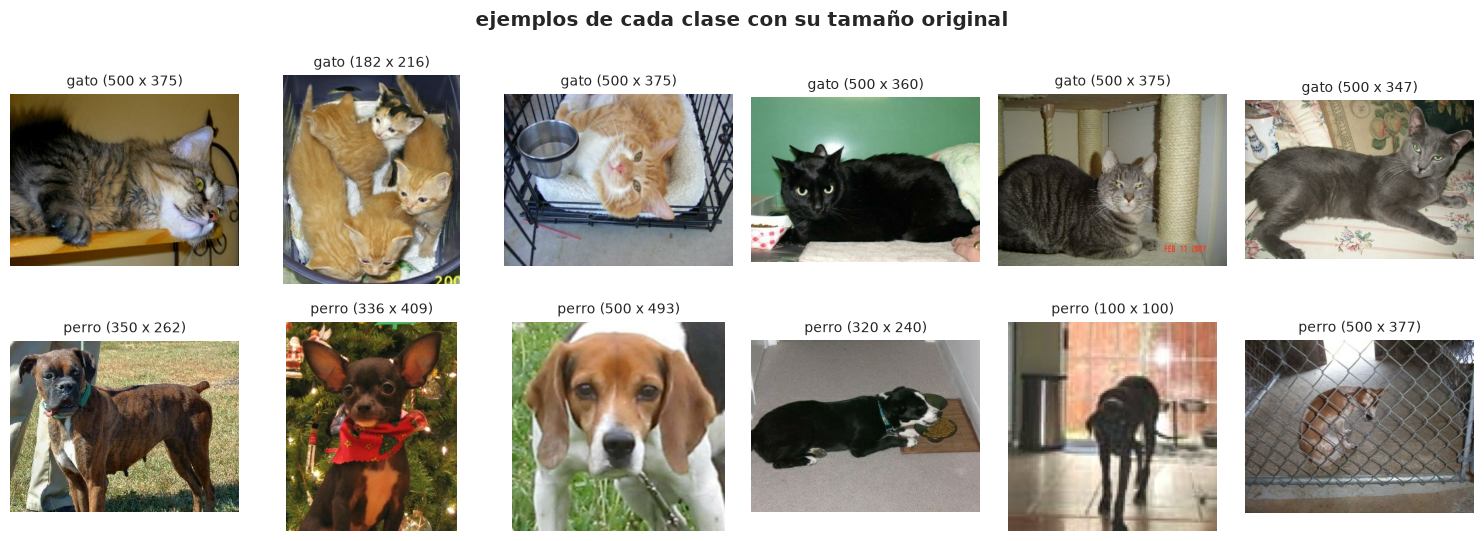

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))

for fila, clase in enumerate(CLASES):
    ejemplos = ds_train.filter(lambda img, y: y == fila).take(6)
    for ax, (img, y) in zip(axes[fila], tfds.as_numpy(ejemplos)):
        ax.imshow(img)
        ax.set_title(f"{clase} ({img.shape[1]} x {img.shape[0]})", fontsize=10)
        ax.axis("off")

plt.suptitle("ejemplos de cada clase con su tamaño original", fontweight="bold")
plt.tight_layout()
plt.show()

Son fotos caseras muy variadas: distintas razas, poses, fondos e iluminación, a veces con personas, jaulas u otros objetos, y cada una con su propio tamaño y proporción. No hay ningún rasgo simple, como un color o una posición, que separe las dos clases a simple vista.

## 4.3 Reparto de clases y tamaño de las imágenes

In [5]:
def medidas(ds, conjunto):
    filas = ds.map(lambda img, y: (tf.shape(img)[0], tf.shape(img)[1], y),
                   num_parallel_calls=tf.data.AUTOTUNE)
    tabla = pd.DataFrame(list(filas.as_numpy_iterator()), columns=["alto", "ancho", "clase"])
    return tabla.assign(conjunto=conjunto)

df = pd.concat([medidas(ds_train, "entrenamiento"), medidas(ds_val, "validacion"), medidas(ds_test, "prueba")],
               ignore_index=True)
df["clase"] = df["clase"].map(dict(enumerate(CLASES)))

display(pd.crosstab(df["conjunto"], df["clase"], margins=True, margins_name="total"))
print("imagenes con algun lado menor de 50 px:", ((df["alto"] < 50) | (df["ancho"] < 50)).sum())
df[["alto", "ancho"]].describe().round(1)

clase,gato,perro,total
conjunto,,,
entrenamiento,8195,8088,16283
prueba,1720,1769,3489
validacion,1743,1747,3490
total,11658,11604,23262


imagenes con algun lado menor de 50 px: 10


,alto,ancho
count,23262.0,23262.0
mean,364.9,410.2
std,96.2,108.0
min,4.0,4.0
25%,316.0,336.0
50%,375.0,467.0
75%,428.0,500.0
max,500.0,500.0


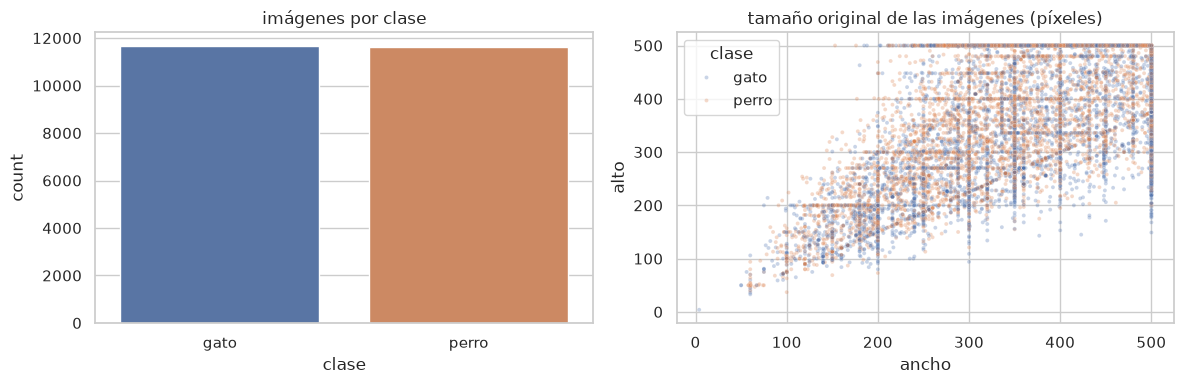

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="clase", hue="clase", order=CLASES, hue_order=CLASES, legend=False, ax=axes[0])
axes[0].set_title("imágenes por clase")

sns.scatterplot(data=df, x="ancho", y="alto", hue="clase", hue_order=CLASES, s=8, alpha=0.3, ax=axes[1])
axes[1].set_title("tamaño original de las imágenes (píxeles)")

plt.tight_layout()
plt.show()

Las clases están muy equilibradas (50,1 % gatos y 49,9 % perros) y el reparto se mantiene en los tres conjuntos, entonces que la exactitud es una métrica justa y no hace falta balancear nada.

El tamaño sí varía mucho. Ninguna imagen supera los 500 píxeles de lado, la mayoría son más horizontales que verticales (mediana de 467 x 375) y hay 10 imágenes diminutas de menos de 50 píxeles que al ampliarlas quedan borrosas, pero son muy poquitas entonces las dejamos

## 4.4 Conclusiones del análisis exploratorio

| # | Hallazgo | Conclusión |
|---|---|---|
| 1 | 23262 imágenes a color con una etiqueta binaria | Es un problema de clasificación binaria de imágenes |
| 2 | Clases repartidas 50,1 % vs 49,9 % en los tres conjuntos | No hace falta balancear y la exactitud es una métrica justa |
| 3 | Cada imagen tiene su propio tamaño (de 4 a 500 píxeles de lado) | Es obligatorio redimensionar todas a un tamaño fijo |
| 4 | Píxeles enteros de 0 a 255 en 3 canales | Hay que aplicar la normalización que espera cada red preentrenada |
| 5 | Mucha variedad de razas, poses, fondos y encuadres | Los píxeles sueltos no sirven, hace falta una red convolucional |
| 6 | Son fotos de perros y gatos, clases que ImageNet ya contiene | Un modelo preentrenado con ImageNet debería transferir muy bien |
| 7 | Hay imágenes diminutas, borrosas o con otros objetos | No se alcanzará el 100 % de exactitud |

# 5. Preparación de los datos

Gracias al EDA sabemos que solo hacen falta dos cosas:

1. Redimensionar todas las imágenes a 160 x 160: la red necesita que todas las entradas tengan la misma forma. Se redimensiona sin recortar, lo que deforma un poco la proporción pero conserva el animal completo.

2. Agrupar en lotes: las imágenes se agrupan en lotes cuyo tamaño se puede cambiar para probar cuál funciona mejor (hiperparámetro). Antes de cada época, se mezclan las imágenes de entrenamiento para que el modelo no las vea siempre en el mismo orden.

La normalización de los píxeles no lo hacemos todavía, lo hacemos luego en cada arquitectura.

Para que la malla sea rápida se usa una muestra de 5000 imágenes de entrenamiento. Los modelos Sfinales sí se entrenan con las 16.283.

In [ ]:
IMG = 160

def redimensionar(img, y):
    return tf.cast(tf.image.resize(img, (IMG, IMG)), tf.uint8), y

def preparar(ds):
    return ds.map(redimensionar, num_parallel_calls=tf.data.AUTOTUNE).cache()

def lotes(ds, batch, barajar=False):
    if barajar:
        ds = ds.shuffle(2000, seed=RANDOM_STATE)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train, val, test = preparar(ds_train), preparar(ds_val), preparar(ds_test)
muestra = preparar(ds_train.take(5000))

print(lotes(train, 32).element_spec)

(TensorSpec(shape=(None, 160, 160, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


# 6. Modelos preentrenados y fine tuning

Se prueban dos arquitecturas preentrenadas con ImageNet (1,2 millones de imágenes de 1.000 clases, entre ellas más de 100 razas de perros y varias de gatos):

- VGG16: 13 capas convolucionales apiladas una tras otra en 5 bloques.
- ResNet50: 50 capas con conexiones residuales (atajos que suman la entrada de un bloque a su salida), lo que permite entrenar redes mucho más profundas.

De cada una se toma solo la base convolucional (include_top=False) y se le añade una cabeza nueva: GlobalAveragePooling -> Dense(unidades, relu) -> Dropout(0,3) -> Dense(1, sigmoid).

El entrenamiento se hace en dos fases:

1. Solo la cabeza: la base está congelada y actúa como extractor de características. Si se entrenara todo desde el inicio, los gradientes grandes de una cabeza recién inicializada dañarían los pesos preentrenados.

2. Fine tuning: se descongela el último bloque convolucional (block5 en VGG16, conv5 en ResNet50) y se sigue entrenando con una tasa de aprendizaje muy baja (1e-5) para adaptar esas características a nuestro problema sin perder lo aprendido.

Las dos fases usan el optimizador Adam y la pérdida binary_crossentropy, la habitual con una salida sigmoide. La base se llama con training=False para que las capas BatchNormalization de ResNet50 sigan usando las estadísticas de ImageNet, y se compila con jit_compile=False porque al crear muchos modelos seguidos la compilación XLA de cada uno gasta más tiempo y memoria de la que ahorra.

In [8]:
apps = tf.keras.applications
ARQUITECTURAS = {
    "VGG16":    (apps.VGG16,    apps.vgg16.preprocess_input,    "block5"),
    "ResNet50": (apps.ResNet50, apps.resnet50.preprocess_input, "conv5"),
}
LR_FINE_TUNING = 1e-5

def compilar(modelo, lr):
    modelo.compile(tf.keras.optimizers.Adam(lr), "binary_crossentropy", metrics=["accuracy"], jit_compile=False)

def crear_modelo(arq, unidades, lr):
    constructor, preprocesar, _ = ARQUITECTURAS[arq]
    tf.keras.utils.set_random_seed(RANDOM_STATE)

    base = constructor(include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
    base.trainable = False

    entrada = tf.keras.Input((IMG, IMG, 3))
    x = preprocesar(entrada)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(unidades, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    salida = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    modelo = tf.keras.Model(entrada, salida)
    compilar(modelo, lr)
    return modelo, base

def descongelar(modelo, base, arq):
    base.trainable = True
    for capa in base.layers:
        capa.trainable = capa.name.startswith(ARQUITECTURAS[arq][2])
    compilar(modelo, LR_FINE_TUNING)

def entrenar(arq, unidades, lr, batch, datos, epocas, verbose=0):
    tr, va = lotes(datos, batch, barajar=True), lotes(val, batch)
    modelo, base = crear_modelo(arq, unidades, lr)
    h1 = modelo.fit(tr, validation_data=va, epochs=epocas, verbose=verbose)      # fase 1: solo la cabeza
    descongelar(modelo, base, arq)
    h2 = modelo.fit(tr, validation_data=va, epochs=epocas, verbose=verbose)      # fase 2: fine tuning
    return modelo, {k: h1.history[k] + h2.history[k] for k in h1.history}

In [9]:
def entrenables(modelo):
    return int(sum(np.prod(w.shape) for w in modelo.trainable_weights))

filas = []
for arq in ARQUITECTURAS:
    modelo, base = crear_modelo(arq, 64, 1e-3)
    fase1 = entrenables(modelo)
    descongelar(modelo, base, arq)
    filas.append({"arquitectura": arq, "capas de la base": len(base.layers),
                  "parametros totales": modelo.count_params(),
                  "entrenables fase 1": fase1, "entrenables fase 2": entrenables(modelo)})

pd.DataFrame(filas).set_index("arquitectura")

,capas de la base,parametros totales,entrenables fase 1,entrenables fase 2
arquitectura,,,,
VGG16,19,14747585,32897,7112321
ResNet50,175,23718913,131201,15107201


En la fase 1 solo se entrena la cabeza, menos del 1 % de los parámetros (unos 33 mil en VGG16 y 131 mil en ResNet50 con 64 unidades). En el fine tuning se suma el último bloque convolucional: 7,1 millones en VGG16 (48 %) y 15,1 millones en ResNet50 (64 %). Las capas anteriores siguen congeladas porque detectan rasgos genéricos (bordes, colores, texturas) que sirven para cualquier imagen.

# 7. Malla de hiperparámetros

Para cada arquitectura se prueban las 8 combinaciones de:

- **unidades** (64, 256): neuronas de la capa densa de la cabeza. Es el equivalente al número de filtros, que en la base no se puede cambiar porque viene fijado por los pesos preentrenados.
- **lr** (0,001, 0,0001): tasa de aprendizaje con la que se entrena la cabeza.
- **batch** (32, 64): imágenes que se procesan antes de cada actualización de pesos.

Son 16 entrenamientos en total. Cada combinación se entrena sobre la muestra de 5.000 imágenes con las dos fases (2 épocas con la base congelada y 2 de fine tuning) y se mide con la exactitud sobre el conjunto de validación completo.

In [10]:
malla = {"unidades": [64, 256], "lr": [1e-3, 1e-4], "batch": [32, 64]}
EPOCAS_MALLA = 2

filas = []
for arq in ARQUITECTURAS:
    for p in ParameterGrid(malla):
        tf.keras.backend.clear_session()
        inicio = time.time()
        _, h = entrenar(arq, p["unidades"], p["lr"], p["batch"], muestra, EPOCAS_MALLA)
        filas.append({"arquitectura": arq, **p,
                      "val_solo_cabeza": h["val_accuracy"][EPOCAS_MALLA - 1],
                      "val_accuracy": h["val_accuracy"][-1],
                      "train_accuracy": h["accuracy"][-1],
                      "segundos": round(time.time() - inicio)})
        print(arq, p, "-> val_accuracy:", round(h["val_accuracy"][-1], 4))

resultados = pd.DataFrame(filas)

VGG16 {'batch': 32, 'lr': 0.001, 'unidades': 64} -> val_accuracy: 0.9794
VGG16 {'batch': 32, 'lr': 0.001, 'unidades': 256} -> val_accuracy: 0.9771
VGG16 {'batch': 32, 'lr': 0.0001, 'unidades': 64} -> val_accuracy: 0.9754
VGG16 {'batch': 32, 'lr': 0.0001, 'unidades': 256} -> val_accuracy: 0.9782
VGG16 {'batch': 64, 'lr': 0.001, 'unidades': 64} -> val_accuracy: 0.9748
VGG16 {'batch': 64, 'lr': 0.001, 'unidades': 256} -> val_accuracy: 0.9768
VGG16 {'batch': 64, 'lr': 0.0001, 'unidades': 64} -> val_accuracy: 0.9722
VGG16 {'batch': 64, 'lr': 0.0001, 'unidades': 256} -> val_accuracy: 0.9759
ResNet50 {'batch': 32, 'lr': 0.001, 'unidades': 64} -> val_accuracy: 0.9805
ResNet50 {'batch': 32, 'lr': 0.001, 'unidades': 256} -> val_accuracy: 0.9802
ResNet50 {'batch': 32, 'lr': 0.0001, 'unidades': 64} -> val_accuracy: 0.9779
ResNet50 {'batch': 32, 'lr': 0.0001, 'unidades': 256} -> val_accuracy: 0.9811
ResNet50 {'batch': 64, 'lr': 0.001, 'unidades': 64} -> val_accuracy: 0.9805
ResNet50 {'batch': 64, '

In [11]:
print("combinaciones probadas:", len(resultados))
resultados.sort_values("val_accuracy", ascending=False).round(4)

combinaciones probadas: 16


,arquitectura,batch,lr,unidades,val_solo_cabeza,val_accuracy,train_accuracy,segundos
11,ResNet50,32,0.0001,256,0.9765,0.9811,0.9876,94
12,ResNet50,64,0.0010,64,0.9782,0.9805,0.9954,93
8,ResNet50,32,0.0010,64,0.9768,0.9805,0.9906,96
14,ResNet50,64,0.0001,64,0.9748,0.9805,0.9832,96
9,ResNet50,32,0.0010,256,0.9802,0.9802,0.9924,93
0,VGG16,32,0.0010,64,0.9699,0.9794,0.9894,98
15,ResNet50,64,0.0001,256,0.9765,0.9791,0.9912,90
13,ResNet50,64,0.0010,256,0.9731,0.9788,0.9944,95
3,VGG16,32,0.0001,256,0.9682,0.9782,0.9774,91
10,ResNet50,32,0.0001,64,0.9759,0.9779,0.9824,93


In [12]:
print("media por arquitectura:")
print(resultados.groupby("arquitectura")[["val_solo_cabeza", "val_accuracy", "segundos"]].mean().round(4))

for h in malla:
    print()
    print("val_accuracy media segun", h)
    print(resultados.groupby(["arquitectura", h])["val_accuracy"].mean().unstack().round(4))

mejores = resultados.loc[resultados.groupby("arquitectura", sort=False)["val_accuracy"].idxmax()]
print()
print("mejor combinacion de cada arquitectura:")
mejores[["arquitectura", "unidades", "lr", "batch", "val_accuracy"]].round(4)

media por arquitectura:
              val_solo_cabeza  val_accuracy  segundos
arquitectura                                         
ResNet50               0.9765        0.9798     93.75
VGG16                  0.9619        0.9762     89.50

val_accuracy media segun unidades
unidades         64      256
arquitectura                
ResNet50      0.9799  0.9798
VGG16         0.9754  0.9770

val_accuracy media segun lr
lr            0.0001  0.0010
arquitectura                
ResNet50      0.9797   0.980
VGG16         0.9754   0.977

val_accuracy media segun batch
batch             32      64
arquitectura                
ResNet50      0.9799  0.9797
VGG16         0.9775  0.9749

mejor combinacion de cada arquitectura:


,arquitectura,unidades,lr,batch,val_accuracy
0,VGG16,64,0.0010,32,0.9794
11,ResNet50,256,0.0001,32,0.9811


Las 16 combinaciones quedan entre 97,2 % y 98,1 % de exactitud en validación. Los modelos son poco sensibles a estos hiperparámetros porque la mayor parte del trabajo ya la hacen los pesos preentrenados.

- **Arquitectura:** ResNet50 supera a VGG16 en promedio (97,98 % frente a 97,62 %), sobre todo con la base congelada (97,65 % frente a 96,19 %). Sus características de ImageNet separan mejor las dos clases sin necesidad de ajustarlas.
- **Fine tuning:** mejora 15 de las 16 combinaciones y en la restante queda igual. A VGG16 le aporta 1,4 puntos de media y a ResNet50 0,3.
- **lr:** con 0,0001 la cabeza de VGG16 no llega a converger en 2 épocas (entre 94,3 % y 96,8 % con la base congelada, frente a 96,6 % a 97,2 % con 0,001), aunque el fine tuning lo compensa después. En ResNet50 da prácticamente igual.
- **batch:** 32 va algo mejor que 64 en VGG16 (97,75 % frente a 97,49 %), porque con lotes pequeños hay el doble de actualizaciones de pesos por época. En ResNet50 no hay diferencia.
- **unidades:** apenas influye, la diferencia es de una o dos décimas.

Hay que leer estas diferencias con cuidado: con 3.490 imágenes de validación, una décima equivale a 3 o 4 imágenes.

# 8. Comparación de las dos arquitecturas

La mejor combinación de cada arquitectura se vuelve a entrenar, ahora con las 16.283 imágenes de entrenamiento y 3 épocas por fase.

El criterio para elegir el mejor modelo es la exactitud en validación, porque las clases están equilibradas y los dos tipos de error importan lo mismo. Si hubiera empate se elige el de menor pérdida en validación.

In [13]:
EPOCAS = 3
modelos, historias = {}, {}

for _, f in mejores.iterrows():
    arq = f["arquitectura"]
    print(arq, "-> unidades:", f["unidades"], ", lr:", f["lr"], ", batch:", f["batch"])
    modelos[arq], historias[arq] = entrenar(arq, int(f["unidades"]), f["lr"], int(f["batch"]),
                                            train, EPOCAS, verbose=2)
    print()

VGG16 -> unidades: 64 , lr: 0.001 , batch: 32
Epoch 1/3
509/509 - 57s - 112ms/step - accuracy: 0.9499 - loss: 0.1862 - val_accuracy: 0.9745 - val_loss: 0.0695
Epoch 2/3
509/509 - 52s - 103ms/step - accuracy: 0.9721 - loss: 0.0737 - val_accuracy: 0.9788 - val_loss: 0.0652
Epoch 3/3
509/509 - 52s - 103ms/step - accuracy: 0.9799 - loss: 0.0549 - val_accuracy: 0.9777 - val_loss: 0.0679
Epoch 1/3
509/509 - 54s - 106ms/step - accuracy: 0.9845 - loss: 0.0433 - val_accuracy: 0.9808 - val_loss: 0.0726
Epoch 2/3
509/509 - 53s - 103ms/step - accuracy: 0.9931 - loss: 0.0207 - val_accuracy: 0.9822 - val_loss: 0.0639
Epoch 3/3
509/509 - 53s - 103ms/step - accuracy: 0.9961 - loss: 0.0126 - val_accuracy: 0.9822 - val_loss: 0.0672

ResNet50 -> unidades: 256 , lr: 0.0001 , batch: 32
Epoch 1/3
509/509 - 47s - 92ms/step - accuracy: 0.9654 - loss: 0.0904 - val_accuracy: 0.9788 - val_loss: 0.0574
Epoch 2/3
509/509 - 40s - 78ms/step - accuracy: 0.9824 - loss: 0.0494 - val_accuracy: 0.9808 - val_loss: 0.0547


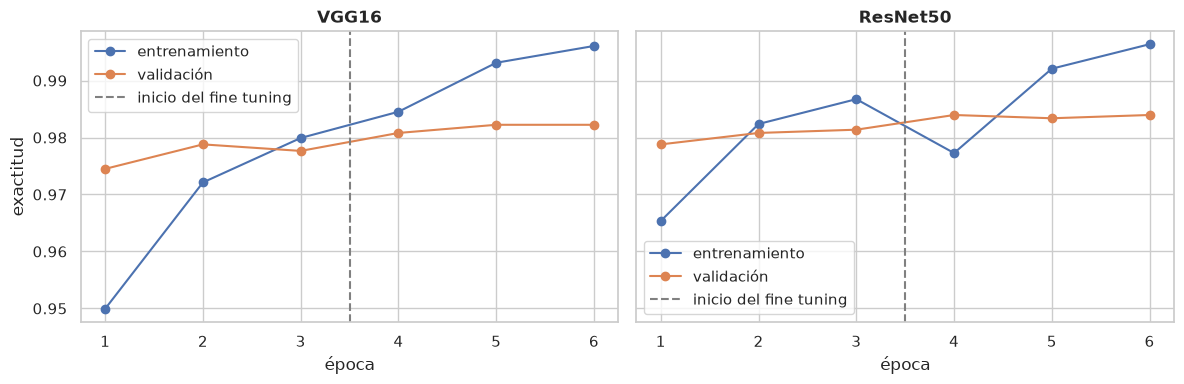

,val_accuracy solo cabeza,val_accuracy con fine tuning,val_loss con fine tuning,train_accuracy final
ResNet50,0.9814,0.9840,0.0509,0.9964
VGG16,0.9777,0.9822,0.0672,0.9961


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
epocas = range(1, 2 * EPOCAS + 1)

for ax, arq in zip(axes, modelos):
    ax.plot(epocas, historias[arq]["accuracy"], "o-", label="entrenamiento")
    ax.plot(epocas, historias[arq]["val_accuracy"], "o-", label="validación")
    ax.axvline(EPOCAS + 0.5, color="gray", ls="--", label="inicio del fine tuning")
    ax.set_title(arq, fontweight="bold")
    ax.set_xlabel("época")
    ax.set_xticks(epocas)
    ax.legend()
axes[0].set_ylabel("exactitud")

plt.tight_layout()
plt.show()

comparativa = pd.DataFrame({arq: {"val_accuracy solo cabeza": h["val_accuracy"][EPOCAS - 1],
                                  "val_accuracy con fine tuning": h["val_accuracy"][-1],
                                  "val_loss con fine tuning": h["val_loss"][-1],
                                  "train_accuracy final": h["accuracy"][-1]}
                            for arq, h in historias.items()}).T
comparativa = comparativa.sort_values(["val_accuracy con fine tuning", "val_loss con fine tuning"],
                                      ascending=[False, True])
comparativa.round(4)

Con todos los datos las dos arquitecturas mejoran respecto a la malla y quedan muy cerca: ResNet50 98,40 % y VGG16 98,22 % de exactitud en validación. La diferencia son 6 imágenes de 3.490, así que en la práctica rinden casi igual.

El fine tuning vuelve a ayudar a las dos: 0,45 puntos en VGG16 y 0,26 en ResNet50. Las curvas muestran que durante el fine tuning la exactitud de entrenamiento sigue subiendo hasta 99,6 % mientras la de validación se estabiliza. Es el inicio de un sobreajuste leve y por eso no tiene sentido entrenar más épocas.

El modelo elegido es ResNet50 por tener la mayor exactitud en validación, que es el criterio fijado de antemano.

# 9. Mejor modelo y evaluación final en test

MEJOR MODELO: ResNet50
Exactitud en validacion: 0.984
Exactitud en test: 0.9799

              precision    recall  f1-score   support

        gato     0.9741    0.9855    0.9798      1720
       perro     0.9857    0.9746    0.9801      1769

    accuracy                         0.9799      3489
   macro avg     0.9799    0.9800    0.9799      3489
weighted avg     0.9800    0.9799    0.9799      3489



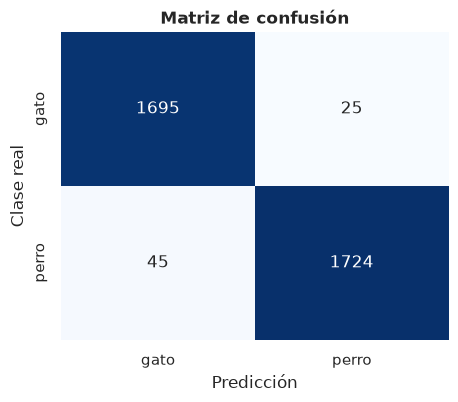

In [15]:
mejor = comparativa.index[0]
mejor_modelo = modelos[mejor]

x_test, y_test = map(np.array, zip(*tfds.as_numpy(test)))
prob = mejor_modelo.predict(x_test, batch_size=64, verbose=0).ravel()
y_pred = (prob > 0.5).astype(int)

print("MEJOR MODELO:", mejor)
print("Exactitud en validacion:", round(comparativa.loc[mejor, "val_accuracy con fine tuning"], 4))
print("Exactitud en test:", round((y_pred == y_test).mean(), 4))
print()
print(classification_report(y_test, y_pred, target_names=CLASES, digits=4))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASES, yticklabels=CLASES)
plt.xlabel("Predicción"); plt.ylabel("Clase real")
plt.title("Matriz de confusión", fontweight="bold")
plt.show()

errores: 70 de 3489 imagenes


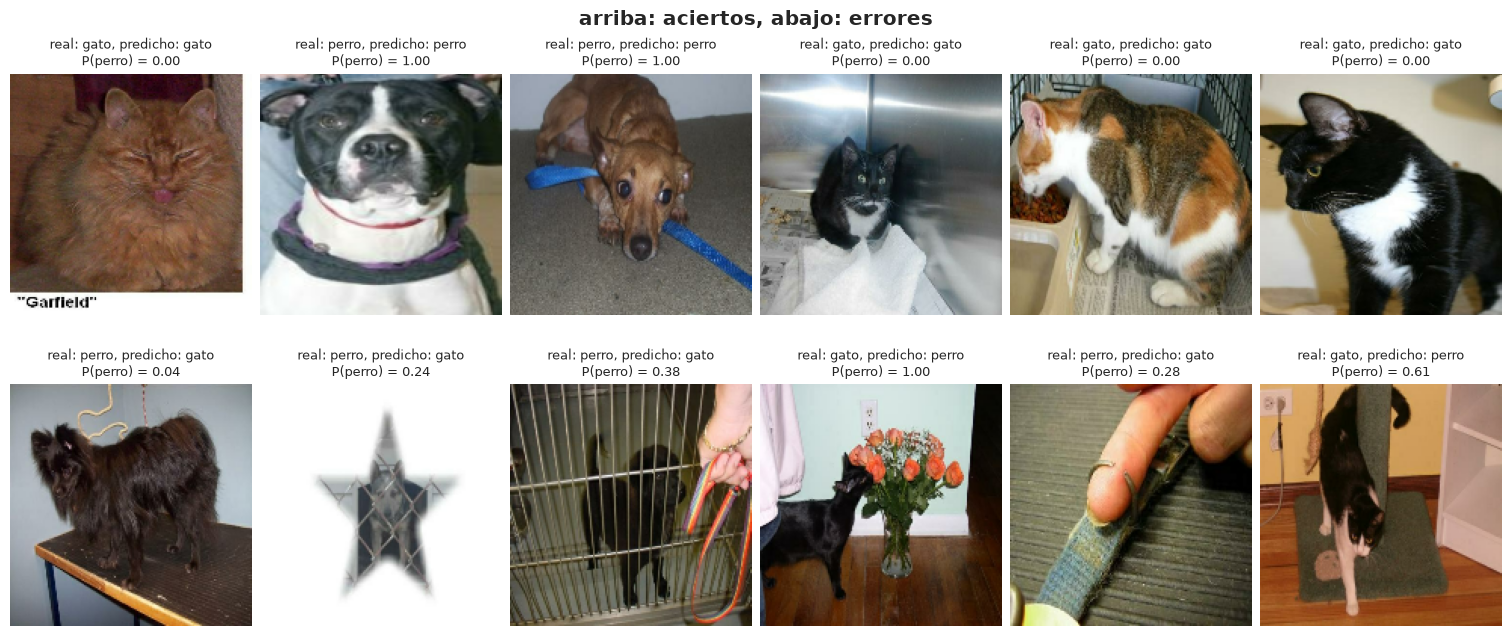

In [16]:
aciertos = np.where(y_pred == y_test)[0]
errores = np.where(y_pred != y_test)[0]
print("errores:", len(errores), "de", len(y_test), "imagenes")

fig, axes = plt.subplots(2, 6, figsize=(15, 6.5), layout="constrained")
for fila, indices in enumerate([aciertos, errores]):
    for ax, i in zip(axes[fila], indices):
        ax.imshow(x_test[i])
        ax.set_title(f"real: {CLASES[y_test[i]]}, predicho: {CLASES[y_pred[i]]}\nP(perro) = {prob[i]:.2f}", fontsize=9)
    for ax in axes[fila]:
        ax.axis("off")

plt.suptitle("arriba: aciertos, abajo: errores", fontweight="bold")
plt.show()

Sobre las 3.489 imágenes de prueba, que no intervinieron en ninguna decisión, ResNet50 acierta el 97,99 % y se equivoca en 70. Queda solo 0,4 puntos por debajo de validación, así que el modelo generaliza bien.

Los errores no están del todo equilibrados: confunde 45 perros con gatos y 25 gatos con perros, por lo que la sensibilidad es algo mayor para gato (98,6 %) que para perro (97,5 %).

Al mirar los errores se ve que muchos son imágenes difíciles incluso para una persona: animales oscuros, tapados por rejas, fotos diminutas o con otros objetos en primer plano. En alguna ni siquiera se distingue el animal, lo que apunta a fotos o etiquetas defectuosas en la propia BD.

# 10. Conclusiones

1. La BD elegida es adecuada para el proyecto: viene etiquetada, con las clases equilibradas (50,1 % y 49,9 %) y lista en TensorFlow Datasets. La única preparación necesaria fue redimensionar las imágenes a 160 x 160.

2. La transferencia de aprendizaje funciona muy bien en este problema. Con la base congelada y solo 5.000 imágenes ya se alcanza entre 94 % y 98 % de exactitud, porque ImageNet contiene muchas razas de perros y gatos.

3. ResNet50 fue mejor que VGG16 tanto en la malla como en el entrenamiento final, aunque por poco (98,40 % frente a 98,22 % en validación). Su ventaja está sobre todo en que sus características preentrenadas ya separan bien las clases con la base congelada.

4. El mejor modelo es ResNet50 con fine tuning del bloque conv5 (256 unidades, lr de 0,0001 y batch de 32): 97,99 % de exactitud en test, con 70 errores en 3.489 imágenes.

5. Los errores que quedan son en su mayoría imágenes ambiguas o defectuosas, por lo que el margen de mejora real es pequeño.